# Лабораторна робота №7
## Тема: Нейронна класифікація зображень у TensorFlow

- **Студент:** Адамчук Ярослав
- **Група:** МІТ-31
- **Номер у списку / Варіант:** 2
- **Індивідуальне завдання (Варіант 2):** 256 нейронів замість 128 у прихованому шарі
- **Фіксований параметр відтворюваності:** SEED = 42
- **Джерело даних:** Fashion-MNIST (Zalando Research, ліцензія MIT)

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Фіксація версій для звіту
print("Версії бібліотек:")
print(f"Python: {sys.version.split()[0]}")
print(f"TensorFlow: {tf.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")

SEED = 42
keras.utils.set_random_seed(SEED)

# Створення папки для збереження моделей
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(parents=True, exist_ok=True)
print("Папка artifacts готова.")

Версії бібліотек:
Python: 3.11.9
TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 3.1.1
Папка artifacts готова.


In [2]:
# Завантаження датасету
(x_dev, y_dev), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "Футболка або топ", "Штани", "Светр", "Сукня",
    "Пальто", "Сандалі", "Сорочка", "Кросівки", "Сумка", "Черевики"
]

# Стратифікований поділ dev (60 000) на train (48 000) та val (12 000)
dev_indices = np.arange(len(x_dev))
train_idx, val_idx = train_test_split(
    dev_indices, test_size=0.20, stratify=y_dev, random_state=SEED
)

x_train, y_train = x_dev[train_idx], y_dev[train_idx]
x_val, y_val = x_dev[val_idx], y_dev[val_idx]

# Препроцесинг: перетворення на float32 без ділення на 255
x_train = x_train.astype("float32")
x_val = x_val.astype("float32")
x_test = x_test.astype("float32")

# Валідаційні перевірки
assert x_train.shape[1:] == (28, 28)
assert np.isfinite(x_train).all()
assert set(np.unique(y_train)) == set(range(10))

print(f"Train: {x_train.shape}, {y_train.shape}")
print(f"Validation: {x_val.shape}, {y_val.shape}")
print(f"Test: {x_test.shape}, {y_test.shape}")
print(f"Значення пікселів: min={x_train.min()}, max={x_train.max()}, dtype={x_train.dtype}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train: (48000, 28, 28), (48000,)
Validation: (12000, 28, 28), (12000,)
Test: (10000, 28, 28), (10000,)
Значення пікселів: min=0.0, max=255.0, dtype=float32


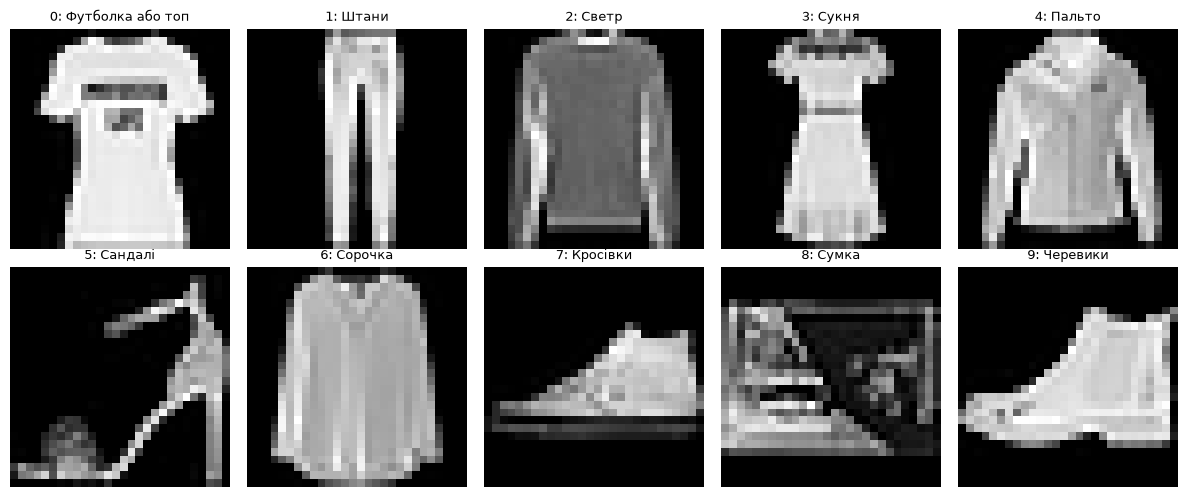

In [3]:
plt.figure(figsize=(12, 5))
for class_idx in range(10):
    sample_idx = np.where(y_train == class_idx)[0][0]
    plt.subplot(2, 5, class_idx + 1)
    plt.imshow(x_train[sample_idx], cmap="gray")
    plt.title(f"{class_idx}: {class_names[class_idx]}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [4]:
# 1. Підготовка даних для scikit-learn (випрямлення матриць у вектори довжиною 784)
x_train_flat = x_train.reshape(len(x_train), -1)
x_val_flat = x_val.reshape(len(x_val), -1)

# 2. Навчання DummyClassifier за мажоритарним класом
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(x_train_flat, y_train)

# 3. Розрахунок валідаційних метрик
dummy_val_preds = dummy.predict(x_val_flat)
dummy_val_acc = accuracy_score(y_val, dummy_val_preds)
dummy_val_f1 = f1_score(y_val, dummy_val_preds, average="macro", zero_division=0)

print(f"DummyClassifier Validation Accuracy: {dummy_val_acc:.4f}")
print(f"DummyClassifier Validation Macro-F1:  {dummy_val_f1:.4f}")

DummyClassifier Validation Accuracy: 0.1000
DummyClassifier Validation Macro-F1:  0.0182


In [5]:
keras.utils.set_random_seed(SEED)

# Базова архітектура мережі
base_model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax")
], name="Base_Model_128")

base_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

base_model.summary()

# Чекпоінт та колбеки для базової моделі
base_checkpoint = "artifacts/base_best.keras"
base_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(base_checkpoint, monitor="val_loss", save_best_only=True)
]

print("\n--- Початок навчання Базової моделі ---")
base_history = base_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=base_callbacks,
    verbose=1
)

Model: "Base_Model_128"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)


--- Початок навчання Базової моделі ---
Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7988 - loss: 0.5887 - val_accuracy: 0.8217 - val_loss: 0.4879
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8515 - loss: 0.4202 - val_accuracy: 0.8403 - val_loss: 0.4431
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8662 - loss: 0.3768 - val_accuracy: 0.8532 - val_loss: 0.4090
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8750 - loss: 0.3487 - val_accuracy: 0.8675 - val_loss: 0.3743
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8816 - loss: 0.3279 - val_accuracy: 0.8726 - val_loss: 0.3596
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8873 - loss: 0.3111 - val_accuracy: 0.8793 - val_loss: 0.3435
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8919 - loss: 0.2962 - val_accuracy: 0.8831 - val_loss: 0.3342
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy:

In [6]:
keras.utils.set_random_seed(SEED)

# Варіант 2: 256 нейронів у прихованому Dense-шарі
variant_model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Rescaling(1./255),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax")
], name="Variant_2_Model_256")

variant_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
)

variant_model.summary()

# Чекпоінт та колбеки для Варіанта 2
variant_checkpoint = "artifacts/variant_2_best.keras"
variant_callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(variant_checkpoint, monitor="val_loss", save_best_only=True)
]

print("\n--- Початок навчання моделі Варіанта 2 ---")
variant_history = variant_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=variant_callbacks,
    verbose=1
)

Model: "Variant_2_Model_256"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)


--- Початок навчання моделі Варіанта 2 ---
Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8067 - loss: 0.5573 - val_accuracy: 0.8382 - val_loss: 0.4483
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8573 - loss: 0.4032 - val_accuracy: 0.8459 - val_loss: 0.4240
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8701 - loss: 0.3619 - val_accuracy: 0.8615 - val_loss: 0.3890
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8794 - loss: 0.3335 - val_accuracy: 0.8732 - val_loss: 0.3592
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8868 - loss: 0.3119 - val_accuracy: 0.8793 - val_loss: 0.3393
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8935 - loss: 0.2945 - val_accuracy: 0.8806 - val_loss: 0.3328
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8969 - loss: 0.2805 - val_accuracy: 0.8849 - val_loss: 0.3247
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accura

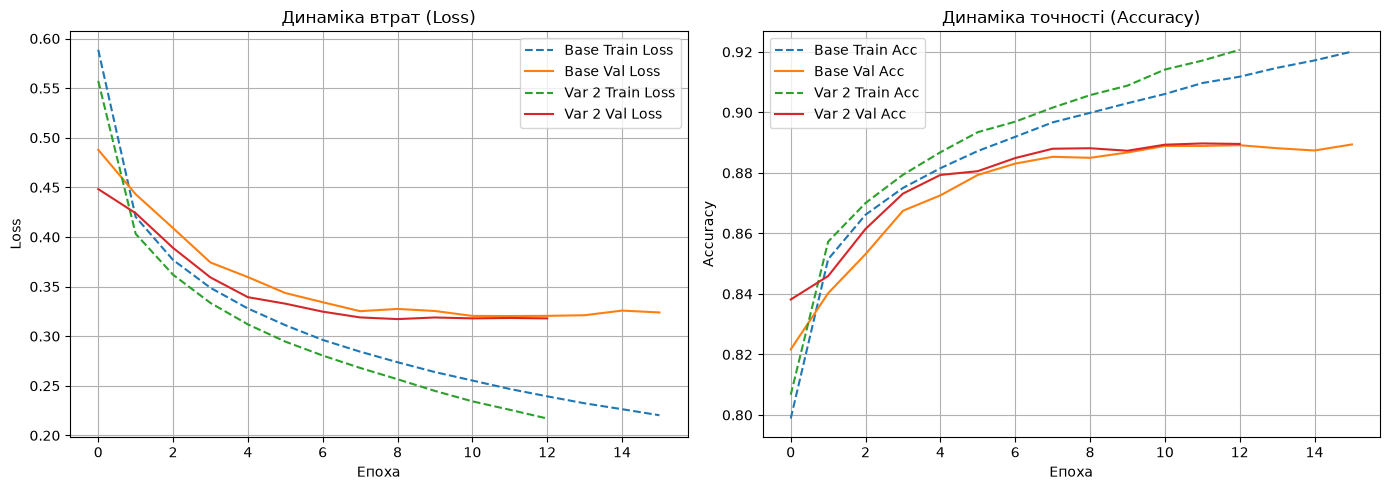

In [8]:
plt.figure(figsize=(14, 5))

# Графік Loss
plt.subplot(1, 2, 1)
plt.plot(base_history.history["loss"], label="Base Train Loss", linestyle="--")
plt.plot(base_history.history["val_loss"], label="Base Val Loss")
plt.plot(variant_history.history["loss"], label="Var 2 Train Loss", linestyle="--")
plt.plot(variant_history.history["val_loss"], label="Var 2 Val Loss")
plt.title("Динаміка втрат (Loss)")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Графік Accuracy
plt.subplot(1, 2, 2)
plt.plot(base_history.history["accuracy"], label="Base Train Acc", linestyle="--")
plt.plot(base_history.history["val_accuracy"], label="Base Val Acc")
plt.plot(variant_history.history["accuracy"], label="Var 2 Train Acc", linestyle="--")
plt.plot(variant_history.history["val_accuracy"], label="Var 2 Val Acc")
plt.title("Динаміка точності (Accuracy)")
plt.xlabel("Епоха")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [9]:
# Завантажуємо найкращий чекпоінт базової мережі
best_base_model = keras.models.load_model(base_checkpoint)

# Отримуємо ймовірності для 5 контрольних прикладів
p_val = best_base_model(x_val[:5], training=False).numpy()
y_onehot = keras.utils.to_categorical(y_val[:5], num_classes=10)

# Порівняння крос-ентропії
loss_sparse = keras.losses.SparseCategoricalCrossentropy()(y_val[:5], p_val)
loss_cat = keras.losses.CategoricalCrossentropy()(y_onehot, p_val)

print(f"Sparse Categorical Loss: {loss_sparse.numpy():.6f}")
print(f"Categorical Loss:        {loss_cat.numpy():.6f}")

np.testing.assert_allclose(loss_sparse.numpy(), loss_cat.numpy(), rtol=1e-5)
print("Assert пройдено: обидва формати міток дають ідентичний loss.")

Sparse Categorical Loss: 0.075395
Categorical Loss:        0.075395
Assert пройдено: обидва формати міток дають ідентичний loss.


In [10]:
def classification_metrics(y, probabilities):
    labels = probabilities.argmax(axis=1)
    ce = float(keras.losses.SparseCategoricalCrossentropy()(y, probabilities).numpy())
    acc = accuracy_score(y, labels)
    f1 = f1_score(y, labels, average="macro", zero_division=0)
    return {"cross_entropy": ce, "accuracy": acc, "macro_f1": f1}

best_variant_model = keras.models.load_model(variant_checkpoint)

# 1. Оцінка на Validation
base_val_probs = best_base_model.predict(x_val, batch_size=256, verbose=0)
var_val_probs = best_variant_model.predict(x_val, batch_size=256, verbose=0)

base_val_m = classification_metrics(y_val, base_val_probs)
var_val_m = classification_metrics(y_val, var_val_probs)

print(f"Базова мережа (Val Cross-Entropy): {base_val_m['cross_entropy']:.4f}")
print(f"Варіант 2     (Val Cross-Entropy): {var_val_m['cross_entropy']:.4f}")

# 2. Вибір моделі за validation loss
if var_val_m["cross_entropy"] < base_val_m["cross_entropy"]:
    selected_model_name = "Варіант 2 Dense(256)"
    selected_model = best_variant_model
    selected_probs_test = best_variant_model.predict(x_test, batch_size=256, verbose=0)
else:
    selected_model_name = "Базова Dense(128)"
    selected_model = best_base_model
    selected_probs_test = best_base_model.predict(x_test, batch_size=256, verbose=0)

print(f"\n--> Обрана фінальна модель: {selected_model_name}")

# 3. Фінальна оцінка на Test (виконується 1 раз)
base_test_probs = best_base_model.predict(x_test, batch_size=256, verbose=0)
var_test_probs = best_variant_model.predict(x_test, batch_size=256, verbose=0)
dummy_test_preds = dummy.predict(x_test.reshape(len(x_test), -1))

base_test_m = classification_metrics(y_test, base_test_probs)
var_test_m = classification_metrics(y_test, var_test_probs)

comparison_df = pd.DataFrame([
    {
        "Модель": "DummyClassifier",
        "Val CE": np.nan, "Val Acc": dummy_val_acc, "Val Macro-F1": dummy_val_f1,
        "Test CE": np.nan, "Test Acc": accuracy_score(y_test, dummy_test_preds),
        "Test Macro-F1": f1_score(y_test, dummy_test_preds, average="macro", zero_division=0),
        "Епох": 0
    },
    {
        "Модель": "Базова Dense(128)",
        "Val CE": base_val_m["cross_entropy"], "Val Acc": base_val_m["accuracy"], "Val Macro-F1": base_val_m["macro_f1"],
        "Test CE": base_test_m["cross_entropy"], "Test Acc": base_test_m["accuracy"], "Test Macro-F1": base_test_m["macro_f1"],
        "Епох": len(base_history.history["loss"])
    },
    {
        "Модель": "Варіант 2 Dense(256)",
        "Val CE": var_val_m["cross_entropy"], "Val Acc": var_val_m["accuracy"], "Val Macro-F1": var_val_m["macro_f1"],
        "Test CE": var_test_m["cross_entropy"], "Test Acc": var_test_m["accuracy"], "Test Macro-F1": var_test_m["macro_f1"],
        "Епох": len(variant_history.history["loss"])
    }
])

comparison_df.to_csv(artifacts_dir / "model_comparison.csv", index=False)
display(comparison_df)

Базова мережа (Val Cross-Entropy): 0.3197
Варіант 2     (Val Cross-Entropy): 0.3165

--> Обрана фінальна модель: Варіант 2 Dense(256)


,Модель,Val CE,Val Acc,Val Macro-F1,Test CE,Test Acc,Test Macro-F1,Епох
0,DummyClassifier,NaN,0.100000,0.018182,NaN,0.1000,0.018182,0
1,Базова Dense(128),0.319741,0.888917,0.889826,0.347813,0.8763,0.877137,16
2,Варіант 2 Dense(256),0.316495,0.888167,0.888634,0.347453,0.8774,0.877789,13


Classification Report:
                  precision    recall  f1-score   support

Футболка або топ       0.87      0.80      0.83      1000
           Штани       0.99      0.97      0.98      1000
           Светр       0.78      0.77      0.78      1000
           Сукня       0.91      0.86      0.88      1000
          Пальто       0.73      0.86      0.79      1000
         Сандалі       0.98      0.94      0.96      1000
         Сорочка       0.69      0.67      0.68      1000
        Кросівки       0.91      0.98      0.94      1000
           Сумка       0.97      0.97      0.97      1000
        Черевики       0.98      0.94      0.96      1000

        accuracy                           0.88     10000
       macro avg       0.88      0.88      0.88     10000
    weighted avg       0.88      0.88      0.88     10000



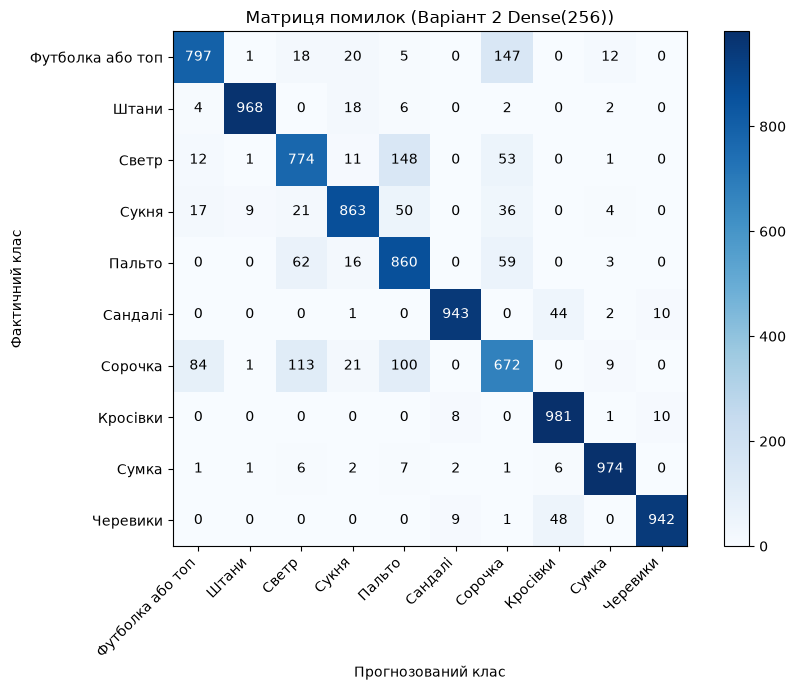

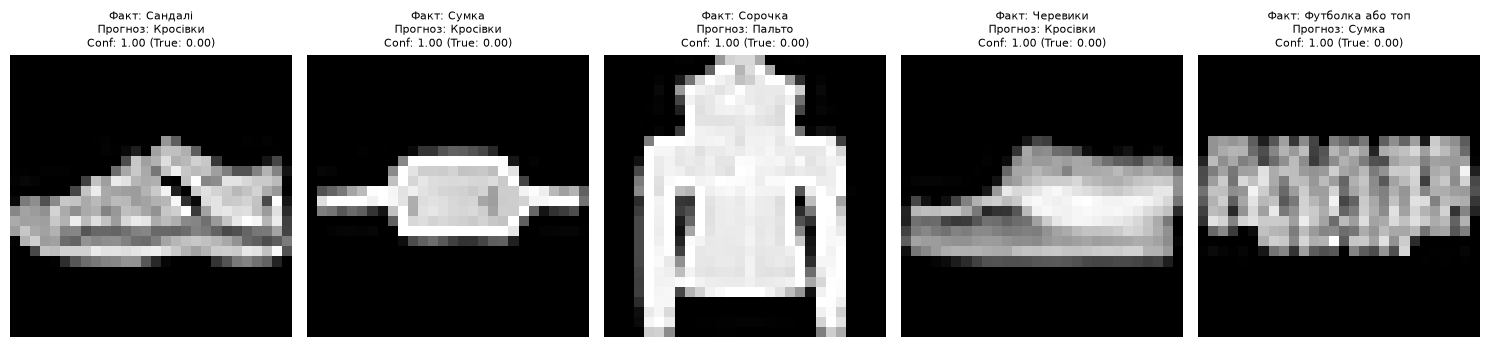

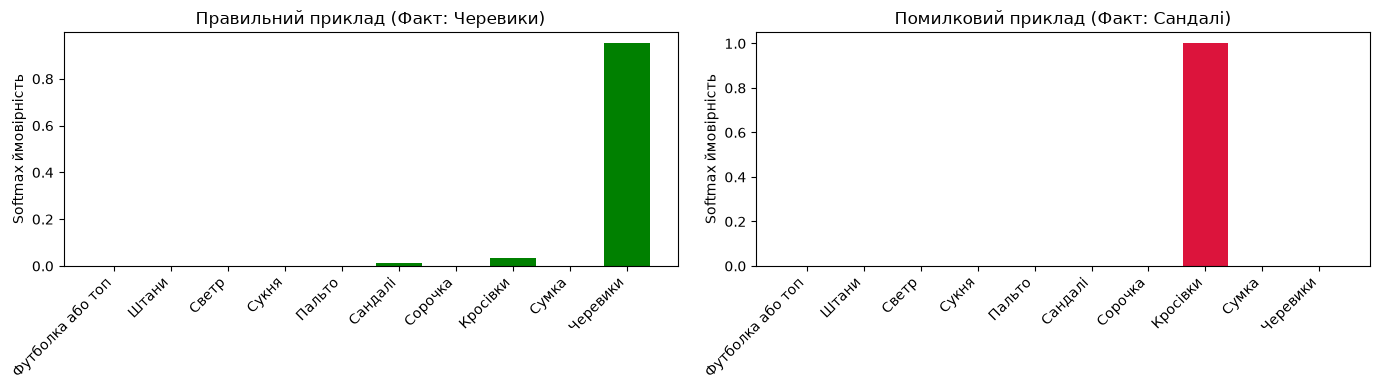

In [11]:
pred = selected_probs_test.argmax(axis=1)
confidence = selected_probs_test.max(axis=1)

print("Classification Report:")
print(classification_report(y_test, pred, target_names=class_names, zero_division=0))

# 1. Побудова матриці невідповідностей
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(9, 7))
plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
plt.title(f"Матриця помилок ({selected_model_name})")
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45, ha="right")
plt.yticks(tick_marks, class_names)
plt.xlabel("Прогнозований клас")
plt.ylabel("Фактичний клас")

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, format(cm[i, j], "d"),
                 ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout()
plt.show()

# 2. 5 найвпевненіших помилок
wrong = np.flatnonzero(pred != y_test)
order = wrong[np.argsort(confidence[wrong])[::-1]]
show_ids = order[:5]

plt.figure(figsize=(15, 3.5))
for idx, img_id in enumerate(show_ids):
    plt.subplot(1, 5, idx + 1)
    plt.imshow(x_test[img_id], cmap="gray")
    true_label = class_names[y_test[img_id]]
    pred_label = class_names[pred[img_id]]
    conf_pred = confidence[img_id]
    conf_true = selected_probs_test[img_id, y_test[img_id]]
    plt.title(f"Факт: {true_label}\nПрогноз: {pred_label}\nConf: {conf_pred:.2f} (True: {conf_true:.2f})", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

# 3. Розподіл імовірностей Softmax для правильного та помилкового прикладів
correct_ids = np.flatnonzero(pred == y_test)
ex_correct = correct_ids[0]
ex_wrong = show_ids[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(10), selected_probs_test[ex_correct], color="green")
axes[0].set_xticks(range(10))
axes[0].set_xticklabels(class_names, rotation=45, ha="right")
axes[0].set_title(f"Правильний приклад (Факт: {class_names[y_test[ex_correct]]})")
axes[0].set_ylabel("Softmax ймовірність")

axes[1].bar(range(10), selected_probs_test[ex_wrong], color="crimson")
axes[1].set_xticks(range(10))
axes[1].set_xticklabels(class_names, rotation=45, ha="right")
axes[1].set_title(f"Помилковий приклад (Факт: {class_names[y_test[ex_wrong]]})")
axes[1].set_ylabel("Softmax ймовірність")

plt.tight_layout()
plt.show()

In [12]:
# 1. Збереження моделі
model_save_path = artifacts_dir / "lab7_model.keras"
selected_model.save(model_save_path)
print(f"Модель збережено в: {model_save_path}")

# 2. Збереження metadata.json
metadata = {
    "class_names": class_names,
    "input_shape": [28, 28],
    "dtype": "float32",
    "input_scale": "0-255",
    "rescaling_layer": "inside_model",
    "seed": SEED,
    "train_indices_count": len(train_idx),
    "val_indices_count": len(val_idx),
    "variant": 2,
    "variant_description": "256 нейронів у прихованому Dense-шарі",
    "selection_criterion": "validation_cross_entropy",
    "selected_model": selected_model_name,
    "packages": {
        "python": sys.version.split()[0],
        "tensorflow": tf.__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__
    }
}

with open(artifacts_dir / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=4)
print("Файл metadata.json успішно сформовано.")

# 3. Перевірка відновлення
probe = x_val[:3]
before = selected_model(probe, training=False).numpy()

restored_model = keras.models.load_model(model_save_path)
after = restored_model(probe, training=False).numpy()

np.testing.assert_allclose(before, after, rtol=1e-5, atol=1e-6)
print("Assert пройдено: виходи збереженої та завантаженої моделей абсолютно збігаються.")

# Тестове передбачення для одного довільного зображення через image[None, ...]
sample_img = x_test[0]
pred_sample = restored_model(sample_img[None, ...], training=False).numpy()
pred_class_idx = pred_sample.argmax(axis=1)[0]
print(f"Тестовий прогноз: клас {pred_class_idx} ({class_names[pred_class_idx]})")

Модель збережено в: artifacts\lab7_model.keras
Файл metadata.json успішно сформовано.
Assert пройдено: виходи збереженої та завантаженої моделей абсолютно збігаються.
Тестовий прогноз: клас 9 (Черевики)
